# Linear Regression — Model Error Analysis

In this notebook, I analyze the predictions made by my Linear Regression model.

Goals:
1. Compare actual and predicted house prices.
2. Calculate prediction errors (residuals).
3. Visualize model performance.
4. Understand where the model makes large errors.

In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv("../01-Data-Preparation/melb_data.csv")
df = df.dropna(subset=["Price"]).copy()

features = [
    "Rooms",
    "Distance",
    "Bedroom2",
    "Bathroom",
    "Car",
    "Landsize",
    "BuildingArea",
    "YearBuilt"
]

X = df[features]
y = df["Price"]

print("Dataset shape:", df.shape)

Dataset shape: (13580, 21)


In [2]:
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

imputer = SimpleImputer(strategy="median")

X_train = imputer.fit_transform(X_train)
X_test = imputer.transform(X_test)

model = LinearRegression()
model.fit(X_train, y_train)

predictions = model.predict(X_test)

print("Baseline model trained.")

Baseline model trained.


In [3]:
comparison = pd.DataFrame({
    "Actual Price": y_test.to_numpy(),
    "Predicted Price": predictions
})

comparison["Error"] = (
    comparison["Actual Price"] - comparison["Predicted Price"]
)

comparison["Absolute Error"] = comparison["Error"].abs()

comparison.head(10)

,Actual Price,Predicted Price,Error,Absolute Error
0,2600000.0,1.240821e+06,1.359179e+06,1.359179e+06
1,620000.0,7.370172e+05,-1.170172e+05,1.170172e+05
2,1000000.0,1.174430e+06,-1.744302e+05,1.744302e+05
3,430000.0,9.752209e+05,-5.452209e+05,5.452209e+05
4,392250.0,7.430603e+05,-3.508103e+05,3.508103e+05
5,700000.0,9.932111e+05,-2.932111e+05,2.932111e+05
6,439000.0,5.652910e+05,-1.262910e+05,1.262910e+05
7,2236000.0,1.841527e+06,3.944734e+05,3.944734e+05
8,671000.0,7.629211e+05,-9.192107e+04,9.192107e+04
9,1870000.0,1.047923e+06,8.220774e+05,8.220774e+05


In [4]:
comparison.sort_values(
    by="Absolute Error",
    ascending=False
).head(10)

,Actual Price,Predicted Price,Error,Absolute Error
2302,1200000.0,5.013725e+06,-3.813725e+06,3.813725e+06
518,2700000.0,6.280088e+06,-3.580088e+06,3.580088e+06
559,4760000.0,1.538625e+06,3.221375e+06,3.221375e+06
1934,5500000.0,2.581158e+06,2.918842e+06,2.918842e+06
1087,5525000.0,2.621447e+06,2.903553e+06,2.903553e+06
2712,6500000.0,3.629863e+06,2.870137e+06,2.870137e+06
145,3800000.0,1.183424e+06,2.616576e+06,2.616576e+06
406,3350000.0,7.967292e+05,2.553271e+06,2.553271e+06
860,3750000.0,1.382616e+06,2.367384e+06,2.367384e+06
110,4000000.0,1.667881e+06,2.332119e+06,2.332119e+06


Matplotlib is building the font cache; this may take a moment.


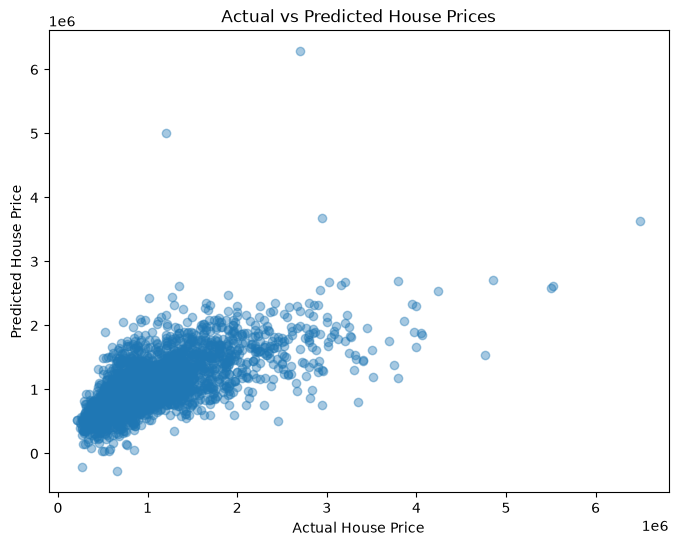

In [6]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(y_test, predictions, alpha=0.4)

plt.xlabel("Actual House Price")
plt.ylabel("Predicted House Price")
plt.title("Actual vs Predicted House Prices")

plt.show()

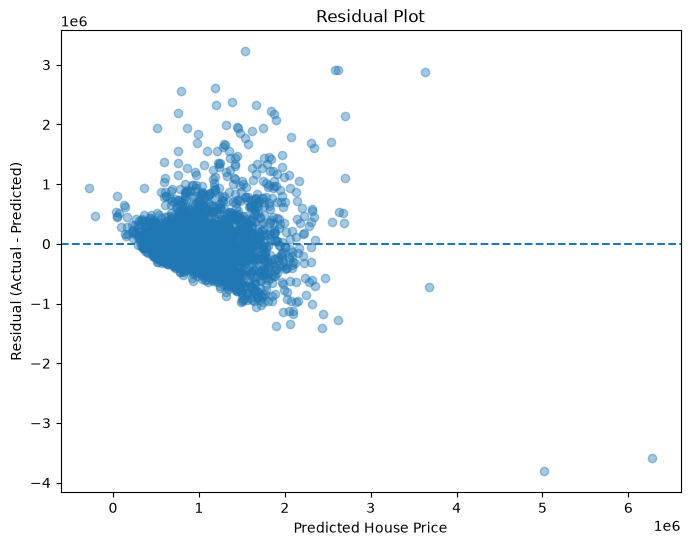

In [7]:
errors = y_test.to_numpy() - predictions

plt.figure(figsize=(8, 6))

plt.scatter(predictions, errors, alpha=0.4)
plt.axhline(y=0, linestyle="--")

plt.xlabel("Predicted House Price")
plt.ylabel("Residual (Actual - Predicted)")
plt.title("Residual Plot")

plt.show()

## What I learned

- Prediction errors show the difference between actual and predicted prices.
- Residuals help identify overprediction and underprediction.
- Scatter plots help visualize model performance.
- A baseline model gives us a reference point for future improvements.

## Next step

Improve the baseline by including categorical features using One-Hot Encoding.